# FRRP Coral Bleaching Pilot — Data Exploration

**Purpose:** Explore the pilot extracted for a first, honest baseline experiment. This notebook is read-only: it loads the pilot CSV and does not modify the CSV or the source SQLite database.

**Research question:** How are bleaching observations distributed across this FRRP subset, and what relationships—if any—appear between environmental measurements and observed bleaching?

**Important scope:** This is observational data from 2005–2016. Relationships in this notebook do not establish future forecasting ability or causality.

In [1]:
from pathlib import Path
import csv
from collections import Counter
import statistics
import matplotlib.pyplot as plt

csv_path = Path("/home/gulrez/Coral-bleaching/data/frrp_baseline_pilot_v0_1.csv")
with csv_path.open("r", newline="", encoding="utf-8-sig") as source:
    reader = csv.DictReader(source)
    columns = reader.fieldnames
    rows = list(reader)

print("CSV absolute path:", csv_path.resolve())
print("Rows:", len(rows))
print("Columns:", len(columns))
print("Header:", ", ".join(columns))

CSV absolute path: /home/gulrez/Coral-bleaching/data/frrp_baseline_pilot_v0_1.csv
Rows: 2394
Columns: 17
Header: Sample_ID, Site_ID, Reef_ID, Date_Year, Date_Month, Date_Day, Depth_m, Latitude_Degrees, Longitude_Degrees, ClimSST, Temperature_Mean, SSTA, SSTA_DHW, TSA, TSA_DHW, Windspeed, Percent_Bleached


## 1. Project introduction and research question

The objective is to understand whether environmental and geographical variables may help explain observed bleaching severity. This first pass establishes data quality and visible distributions before any modelling or temporal validation.

## 2. Dataset overview

The extraction should contain 2,394 observations covering 2005–2016. The following calculations verify the row count, years, unique sites and complete exact-row/`Sample_ID` checks.

In [3]:
years = [int(float(row["Date_Year"])) for row in rows]
year_counts = Counter(years)

print("Observation years:", min(years), "-", max(years))
print("Year counts:", sorted(year_counts.items()))
print("Unique Sample_ID:", len({row["Sample_ID"] for row in rows}))
print("Unique Site_ID:", len({row["Site_ID"] for row in rows}))
print(
    "Exact duplicate rows:",
    len(rows) - len({tuple(row[c] for c in columns) for row in rows}),
)
print(
    "Duplicate extra rows by Sample_ID:",
    len(rows) - len({row["Sample_ID"] for row in rows}),
)

Observation years: 2005 - 2016
Year counts: [(2005, 96), (2006, 173), (2007, 153), (2008, 210), (2009, 259), (2010, 285), (2011, 239), (2012, 237), (2013, 98), (2014, 174), (2015, 277), (2016, 193)]
Unique Sample_ID: 2394
Unique Site_ID: 2299
Exact duplicate rows: 0
Duplicate extra rows by Sample_ID: 0


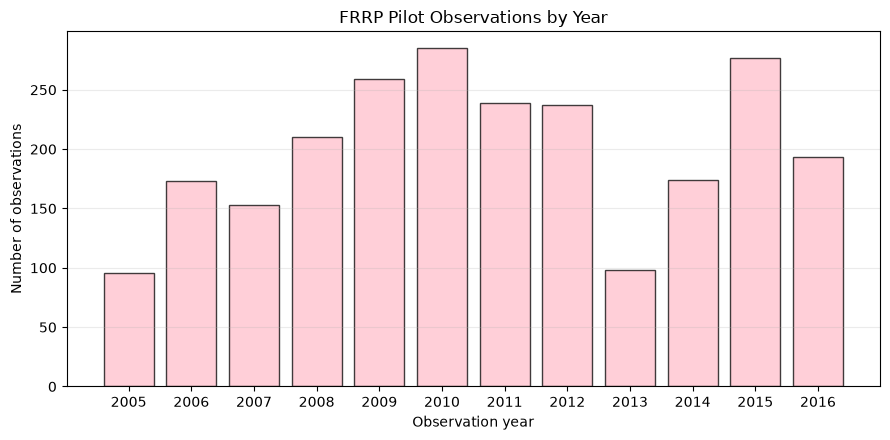

In [4]:
# Year distribution
year_labels = sorted(year_counts)
year_values = [year_counts[y] for y in year_labels]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(year_labels, year_values, color="pink", edgecolor="black", alpha=0.75)
ax.set_title("FRRP Pilot Observations by Year")
ax.set_xlabel("Observation year")
ax.set_ylabel("Number of observations")
ax.set_xticks(year_labels)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**What this chart shows:** The pilot is not evenly distributed across years. It is largest in 2015 and smallest in 2005, so later exploratory relationships should be interpreted with uneven year coverage.

## 3. Data quality summary

Missing values are reported from the exact CSV. No missing values were replaced with zero. `Reef_ID` is blank for every row, while `Percent_Bleached` has no missing values.

In [5]:
missing = {}
for column in columns:
    missing[column] = sum(
        row[column].strip() == ""
        or row[column].strip().lower() in {"na", "nan", "null", "none"}
        for row in rows
    )

for column, count in missing.items():
    print(f"{column}: {count} missing")

print("Reef_ID missing:", missing["Reef_ID"])
print("ClimSST = 262.15:", sum(float(row["ClimSST"]) == 262.15 for row in rows))

Sample_ID: 0 missing
Site_ID: 0 missing
Reef_ID: 2394 missing
Date_Year: 0 missing
Date_Month: 0 missing
Date_Day: 0 missing
Depth_m: 0 missing
Latitude_Degrees: 0 missing
Longitude_Degrees: 0 missing
ClimSST: 0 missing
Temperature_Mean: 0 missing
SSTA: 0 missing
SSTA_DHW: 0 missing
TSA: 0 missing
TSA_DHW: 0 missing
Windspeed: 0 missing
Percent_Bleached: 0 missing
Reef_ID missing: 2394
ClimSST = 262.15: 187


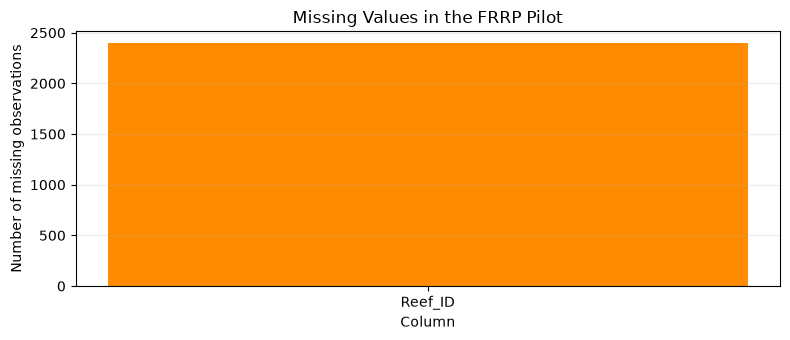

In [6]:
# Missing-value bar chart (blank, NA, NaN and NULL strings)
missing_columns = [c for c, n in missing.items() if n > 0]
missing_counts = [missing[c] for c in missing_columns]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(missing_columns, missing_counts, color="darkorange")
ax.set_title("Missing Values in the FRRP Pilot")
ax.set_xlabel("Column")
ax.set_ylabel("Number of missing observations")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**What this chart shows:** Only `Reef_ID` has missing values in the pilot under the audit's missing-value definition. No populated numeric column is being silently converted to zero by this notebook.

## 4. Target distribution

`Percent_Bleached` is a bounded outcome from 0 to 100. The distribution is right-skewed and includes 201 exact zero values and 2 exact 100 values.

In [7]:
target = [float(row["Percent_Bleached"]) for row in rows]

print("Count:", len(target))
print("Minimum:", min(target))
print("Maximum:", max(target))
print("Mean:", statistics.fmean(target))
print("Median:", statistics.median(target))
print("Zeros:", sum(value == 0 for value in target))
print("100 percent:", sum(value == 100 for value in target))

Count: 2394
Minimum: 0.0
Maximum: 100.0
Mean: 15.30548872180451
Median: 10.26
Zeros: 201
100 percent: 2


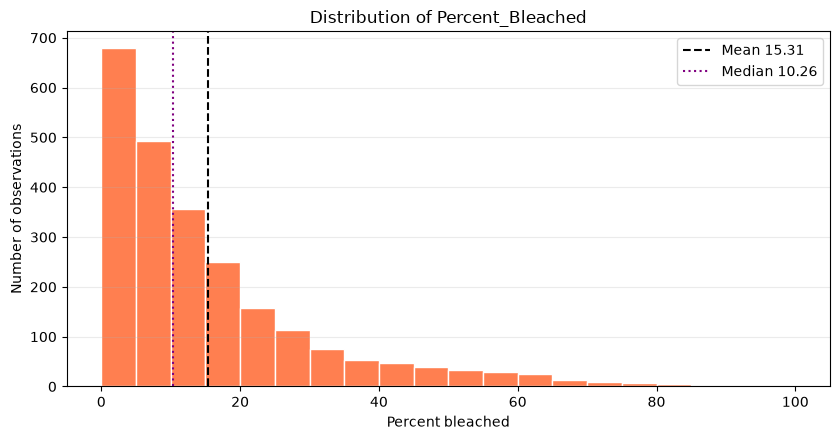

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.hist(target, bins=20, range=(0, 100), color="coral", edgecolor="white")
ax.axvline(
    statistics.fmean(target),
    color="black",
    linestyle="--",
    label=f"Mean {statistics.fmean(target):.2f}",
)
ax.axvline(
    statistics.median(target),
    color="purple",
    linestyle=":",
    label=f"Median {statistics.median(target):.2f}",
)
ax.set_title("Distribution of Percent_Bleached")
ax.set_xlabel("Percent bleached")
ax.set_ylabel("Number of observations")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**What this chart shows:** Bleaching observations are concentrated near the lower end of the 0–100 scale. The mean is higher than the median, indicating right skew, while exact zero and 100 remain possible boundary observations.

## 5. Environmental feature distributions

The next plots summarize the available depth, anomaly and thermal stress fields. Interpret `ClimSST = 262.15` cautiously: it was found as 262.15 in the original database and may be an implausible value or source artifact.

In [9]:
feature_columns = [
    "Depth_m",
    "ClimSST",
    "Temperature_Mean",
    "SSTA",
    "SSTA_DHW",
    "TSA",
    "TSA_DHW",
    "Windspeed",
]
for column in feature_columns:
    values = [float(row[column]) for row in rows]
    print(
        f"{column}: n={len(values)}, min={min(values):.4g}, max={max(values):.4g}, mean={statistics.fmean(values):.4g}"
    )

Depth_m: n=2394, min=1.2, max=29.9, mean=8.133
ClimSST: n=2394, min=262.1, max=302.7, mean=297.4
Temperature_Mean: n=2394, min=298.9, max=299.9, mean=299.7
SSTA: n=2394, min=-4.05, max=5.9, mean=0.4883
SSTA_DHW: n=2394, min=0, max=53.6, mean=4.703
TSA: n=2394, min=-10.26, max=5.9, mean=-0.5191
TSA_DHW: n=2394, min=0, max=52.45, mean=2.684
Windspeed: n=2394, min=1, max=10, mean=3.888


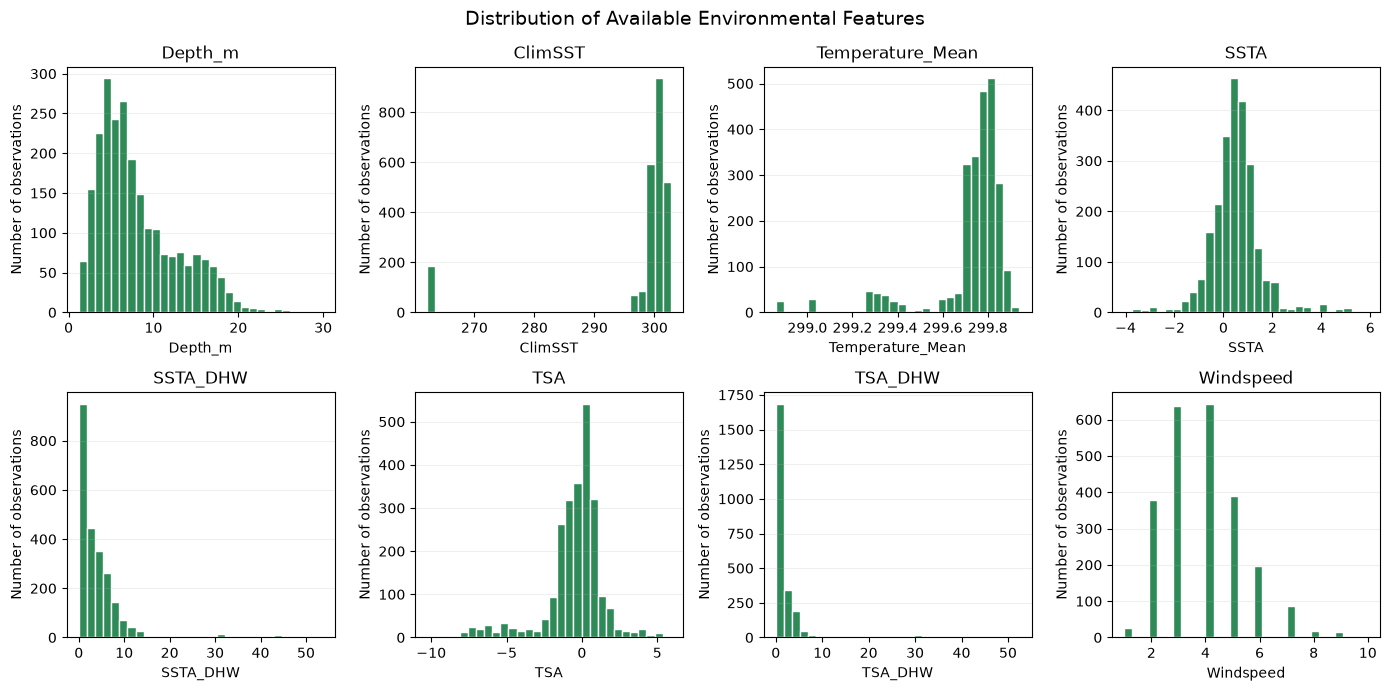

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
feature_columns = [
    "Depth_m",
    "ClimSST",
    "Temperature_Mean",
    "SSTA",
    "SSTA_DHW",
    "TSA",
    "TSA_DHW",
    "Windspeed",
]

for ax, column in zip(axes.ravel(), feature_columns):
    values = [float(row[column]) for row in rows]
    ax.hist(values, bins=30, color="seagreen", edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Number of observations")
    ax.grid(axis="y", alpha=0.20)

fig.suptitle("Distribution of Available Environmental Features", fontsize=14)
plt.tight_layout()
plt.show()

**What this chart shows:** Each environmental feature has its own scale and shape. `ClimSST` visibly separates 262.15 from the dominant Kelvin values, while the anomalies and DHW fields are not normally distributed and should not be assumed to be so.

In [13]:
# Read-only summary table: one row per key audit item
summary_items = [
    ("Rows", len(rows)),
    ("Columns", len(columns)),
    ("Unique Sample_ID", len({r["Sample_ID"] for r in rows})),
    ("Unique Site_ID", len({r["Site_ID"] for r in rows})),
    ("Years", f"{min(years)}-{max(years)}"),
    ("Target mean", round(statistics.fmean(target), 4)),
    ("Target median", round(statistics.median(target), 4)),
    ("Reef_ID missing", missing["Reef_ID"]),
    ("ClimSST 262.15", sum(float(row["ClimSST"])==262.15 for row in rows)),
]

print("Audit summary")
for label, value in summary_items:
    print(f"{label}: {value}")

Audit summary
Rows: 2394
Columns: 17
Unique Sample_ID: 2394
Unique Site_ID: 2299
Years: 2005-2016
Target mean: 15.3055
Target median: 10.26
Reef_ID missing: 2394
ClimSST 262.15: 187


## Thermal Stress and Bleaching Relationships

This section examines whether larger thermal-stress measurements tend to occur alongside larger observed bleaching percentages. It reports Pearson correlations and scatter plots as descriptive association checks only, and does not establish causality or future predictive performance.

In [ ]:
# Pearson correlation is a lightweight descriptive measure.
def pearson(x, y):
    n = len(x)
    mx = sum(x) / n
    my = sum(y) / n
    numerator = sum((a - mx) * (b - my) for a, b in zip(x, y))
    denominator = (sum((a - mx) ** 2 for a in x) * sum((b - my) ** 2 for b in y)) ** 0.5
    return numerator / denominator if denominator else float("nan")


thermal_features = ["Temperature_Mean", "SSTA", "SSTA_DHW", "TSA", "TSA_DHW"]
bleaching = [float(row["Percent_Bleached"]) for row in rows]

print("Pearson correlations with Percent_Bleached")
for feature in thermal_features:
    values = [float(row[feature]) for row in rows]
    print(f"{feature}: {pearson(values, bleaching):+.3f}")

# Sensitivity investigation: exclude the 187 original-DB ClimSST=262.15 records from this comparison
# This does not classify or correct those records.
subset = [row for row in rows if float(row["ClimSST"]) != 262.15]
subset_bleaching = [float(row["Percent_Bleached"]) for row in subset]
print("\nSensitivity comparison excluding ClimSST=262.15 records (n=%d)" % len(subset))
for feature in thermal_features:
    values = [float(row[feature]) for row in subset]
    print(f"{feature}: {pearson(values, subset_bleaching):+.3f}")

Pearson correlations with Percent_Bleached
Temperature_Mean: -0.037
SSTA: +0.162
SSTA_DHW: +0.193
TSA: +0.198
TSA_DHW: +0.162

After excluding ClimSST=262.15 records (n=2207)
Temperature_Mean: -0.043
SSTA: +0.158
SSTA_DHW: +0.191
TSA: +0.191
TSA_DHW: +0.158


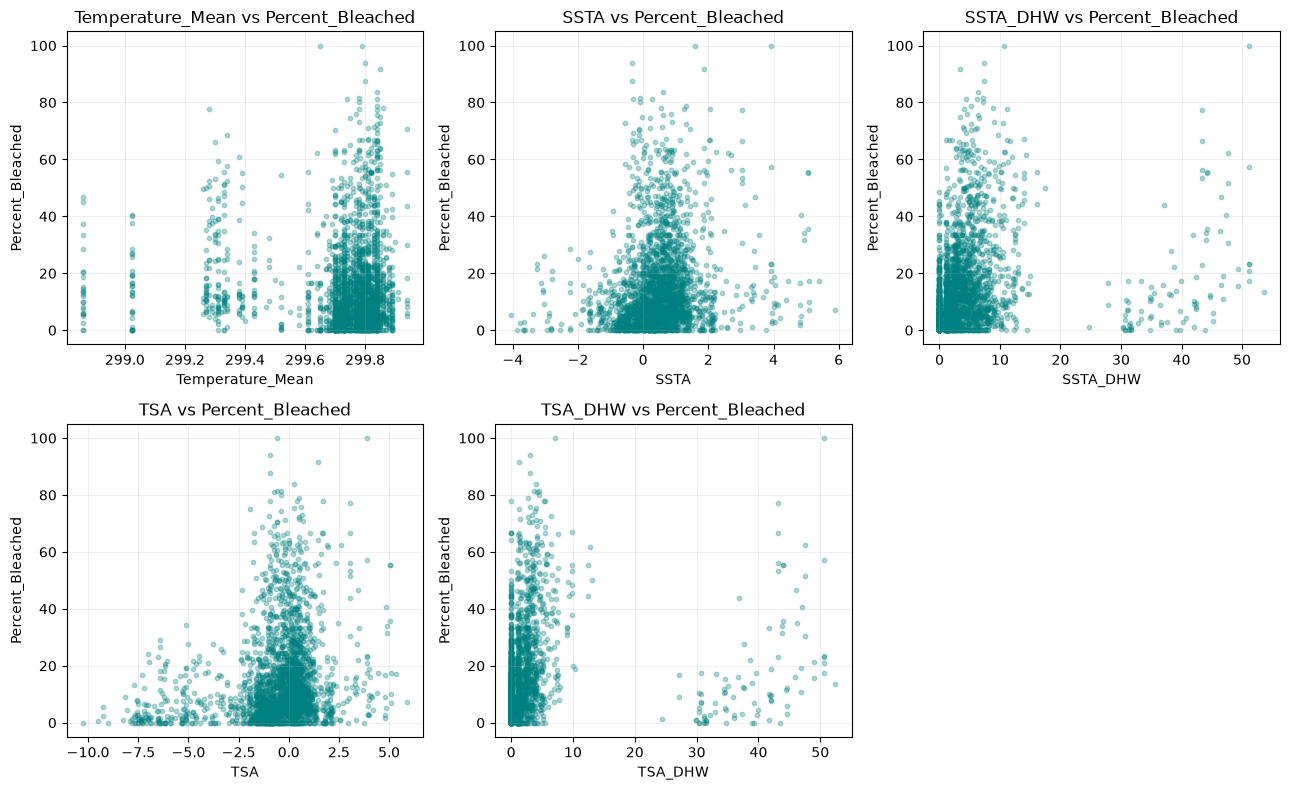

In [ ]:
thermal_features = ["Temperature_Mean", "SSTA", "SSTA_DHW", "TSA", "TSA_DHW"]
bleaching = [float(row["Percent_Bleached"]) for row in rows]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, feature in zip(axes.ravel(), thermal_features):
    values = [float(row[feature]) for row in rows]
    ax.scatter(values, bleaching, s=10, alpha=0.30, color="teal")
    ax.set_title(f"{feature} vs Percent_Bleached")
    ax.set_xlabel(feature)
    ax.set_ylabel("Percent_Bleached")
    ax.grid(alpha=0.20)

axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**What this chart shows:** The four-degree/stress variables do not show a consistently strong upward relationship in these plots. Their Pearson coefficients and the visual scatter should be interpreted alongside seasonal timing, site structure and the uncertain environmental aggregation period.

## 7. Bleaching over Time

This section summarizes the target for every observed year rather than relying on a single pooled average. Repeated observations at sites are retained; no model or temporal split is fitted here.

In [ ]:
annual_groups = {}
for row in rows:
    year = int(float(row["Date_Year"]))
    annual_groups.setdefault(year, []).append(float(row["Percent_Bleached"]))

annual_years = sorted(annual_groups)
annual_means = [sum(annual_groups[y]) / len(annual_groups[y]) for y in annual_years]
annual_medians = [statistics.median(annual_groups[y]) for y in annual_years]
annual_counts = [len(annual_groups[y]) for y in annual_years]

print("Year: n, mean, median")
for year, n, mean, median in zip(
    annual_years, annual_counts, annual_means, annual_medians
):
    print(f"{year}: {n}, {mean:.3f}, {median:.3f}")

Year: n, mean, median
2005: 96, 23.042, 21.610
2006: 173, 6.031, 4.390
2007: 153, 14.902, 12.280
2008: 210, 7.013, 5.540
2009: 259, 12.130, 11.050
2010: 285, 8.685, 6.250
2011: 239, 15.976, 14.320
2012: 237, 5.879, 4.630
2013: 98, 6.220, 4.170
2014: 174, 43.603, 44.885
2015: 277, 30.211, 28.070
2016: 193, 11.604, 10.260


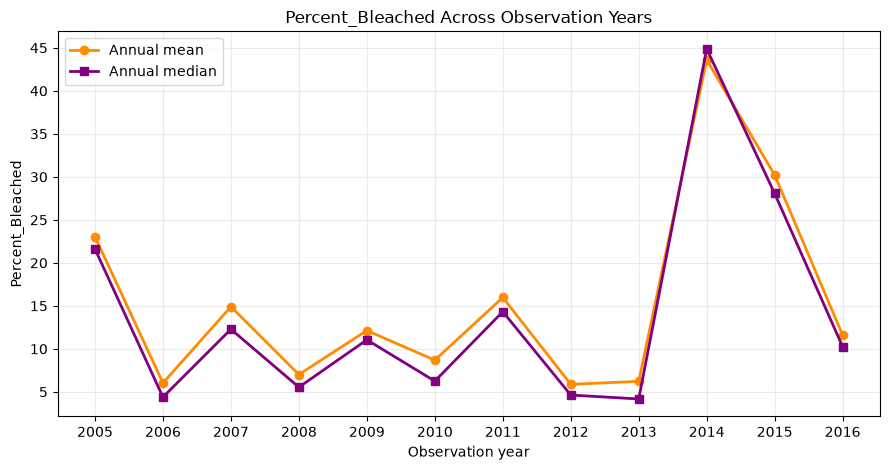

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(
    annual_years,
    annual_means,
    marker="o",
    linewidth=2,
    color="darkorange",
    label="Annual mean",
)
ax.plot(
    annual_years,
    annual_medians,
    marker="s",
    linewidth=2,
    color="purple",
    label="Annual median",
)
ax.set_title("Percent_Bleached Across Observation Years")
ax.set_xlabel("Observation year")
ax.set_ylabel("Percent_Bleached")
ax.set_xticks(annual_years)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

**What this chart shows:** Both annual mean and median change across years, but sample counts vary substantially. Year-to-year differences should not yet be interpreted as temporal forecasts or trends because coverage and site composition differ.

## 8. Pearson Feature Correlations

This section checks linear relationships among numeric environmental variables. Pearson correlation only measures linear association and cannot capture every possible relationship. Strong correlations may indicate redundant measurements or shared aggregation sources, especially among SSTA/SSTA_DHW and TSA/TSA_DHW.

The heatmap is descriptive: unusual values can influence the coefficients, and these results should not be interpreted as evidence of causality or as a complete measure of variable dependence.

In [ ]:
correlation_features = [
    "Temperature_Mean",
    "ClimSST",
    "SSTA",
    "SSTA_DHW",
    "TSA",
    "TSA_DHW",
    "Windspeed",
    "Depth_m",
]
correlation_matrix = []

for left in correlation_features:
    left_values = [float(row[left]) for row in rows]
    correlation_matrix.append(
        [
            pearson(left_values, [float(row[right]) for row in rows])
            for right in correlation_features
        ]
    )

print("Strong absolute correlations (excluding |r|=1.000 diagonal):")
for i, left in enumerate(correlation_features):
    for j, right in enumerate(correlation_features):
        if j <= i:
            continue
        value = correlation_matrix[i][j]
        if abs(value) >= 0.70:
            print(f"{left} vs {right}: {value:+.3f}")

Strong absolute correlations (excluding |r|=1.000 diagonal):
SSTA_DHW vs TSA_DHW: +0.952


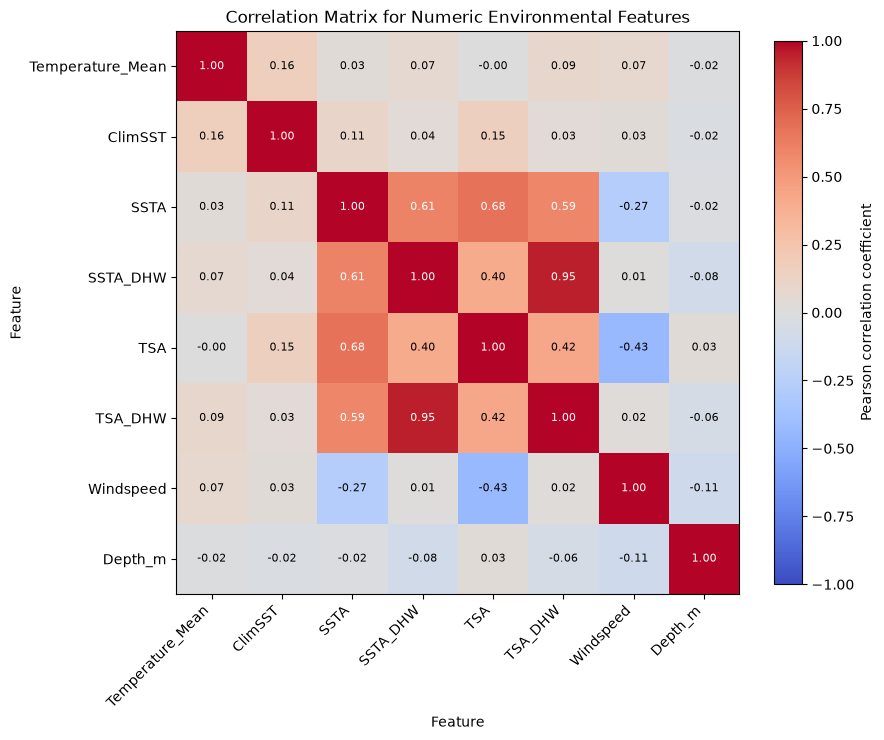

In [ ]:
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(correlation_matrix, vmin=-1, vmax=1, cmap="coolwarm", aspect="equal")
ax.set_title("Pearson Correlation Matrix for Numeric Environmental Features")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
ax.set_xticks(range(len(correlation_features)))
ax.set_yticks(range(len(correlation_features)))
ax.set_xticklabels(correlation_features, rotation=45, ha="right")
ax.set_yticklabels(correlation_features)

for i in range(len(correlation_features)):
    for j in range(len(correlation_features)):
        ax.text(
            j,
            i,
            f"{correlation_matrix[i][j]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(correlation_matrix[i][j]) > 0.55 else "black",
        )

colorbar = fig.colorbar(image, ax=ax, shrink=0.82)
colorbar.set_label("Pearson correlation coefficient")
plt.tight_layout()
plt.show()

**What this chart shows:** This heatmap describes linear Pearson correlations among the pilot features. It does not detect every kind of relationship, and unusual values can influence the coefficients. The 262.15 `ClimSST` observations are preserved and were investigated separately in the thermal-stress sensitivity analysis; their presence is not presented as proof that those records are erroneous. A strong or weak correlation here should not be read as causal evidence.

## 9. Findings and Unresolved Limitations

### Thermal stress versus bleaching
- The scatter plots and correlations provide descriptive association checks only.
- Apparent coefficients may be affected by seasonal timing, site structure and environmental measurement timing.
- The 262.15 `ClimSST` sensitivity calculation compares the pilot with those 187 observations excluded. The original data remain intact, and this investigation does not prove that the values are erroneous.

### Bleaching over time
- Annual means and medians show variation over 2005–2016.
- Unequal observation counts and differing site coverage prevent a causal or forecasting interpretation.

### Feature correlations
- The Pearson correlation matrix can identify linear redundancy or strongly related predictors.
- Highly correlated stress variables may require careful feature selection later if modelling begins.
- These correlations describe the pilot only, do not capture every nonlinear relationship, and are not adjusted for year or site.